In [17]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

teams = [
    "Romania", "Argentina", "France", "Germany", "Spain", "Brazil",
    "England", "Netherlands", "Italy", "Belgium", "Croatia", "Uruguay",
    "Mexico", "USA", "Japan", "South Korea", "Morocco", "Senegal",
    "Switzerland", "Denmark", "Colombia", "Chile", "Poland", "Serbia",
    "Ivory Coast", "Nigeria", "Australia", "Canada", "Portugal", "Turkey"
]

team_ranks = {
    "France": 1,
    "Spain": 2,
    "Argentina": 3,
    "England": 4,
    "Portugal": 5,
    "Brazil": 6,
    "Netherlands": 7,
    "Belgium": 8,
    "Germany": 9,
    "Croatia": 10,
    "Morocco": 11,
    "Italy": 12,
    "Colombia": 13,
    "USA": 14,
    "Mexico": 15,
    "Uruguay": 16,
    "Japan": 17,
    "Switzerland": 18,
    "Denmark": 19,
    "Senegal": 20,
    "South Korea": 22,
    "Poland": 24,
    "Serbia": 32,
    "Turkey": 26,
    "Australia": 25,
    "Canada": 27,
    "Nigeria": 28,
    "Ivory Coast": 41,
    "Chile": 50,
    "Romania": 47
}

importance_levels = ["friendly", "qualifier", "continental_cup", "world_cup"]


def generate_match(match_id):
    home_team, away_team = np.random.choice(teams, size=2, replace=False)

    home_rank = team_ranks[home_team] + np.random.randint(-3, 4)
    away_rank = team_ranks[away_team] + np.random.randint(-3, 4)

    home_rank = max(1, min(100, home_rank))
    away_rank = max(1, min(100, away_rank))

    rank_difference = abs(away_rank - home_rank)
    home_attack_strength = np.round(np.random.uniform(0.4, 1.0), 2)
    away_attack_strength = np.round(np.random.uniform(0.4, 1.0), 2)

    home_defense_strength = np.round(np.random.uniform(0.4, 1.0), 2)
    away_defense_strength = np.round(np.random.uniform(0.4, 1.0), 2)

    home_form_last_5 = np.round(np.random.uniform(0.0, 1.0), 2)
    away_form_last_5 = np.round(np.random.uniform(0.0, 1.0), 2)

    neutral_location = np.random.choice([0, 1], p=[0.75, 0.25])

    importance_level = np.random.choice(
        importance_levels,
        p=[0.35, 0.30, 0.20, 0.15]
    )

    home_advantage = 0.25 if neutral_location == 0 else 0.0

    rank_factor_home = (101 - home_rank) / 100
    rank_factor_away = (101 - away_rank) / 100

    importance_factor = {
        "friendly": 0.75,
        "qualifier": 0.90,
        "continental_cup": 1.00,
        "world_cup": 1.15
    }[importance_level]

    expected_goals_home = (
        0.9
        + 1.0 * home_attack_strength
        - 0.5 * away_defense_strength
        + 0.7 * home_form_last_5
        + 0.4 * rank_factor_home
        + home_advantage
    ) * importance_factor

    expected_goals_away = (
        0.9
        + 1.0 * away_attack_strength
        - 0.5 * home_defense_strength
        + 0.7 * away_form_last_5
        + 0.4 * rank_factor_away
    ) * importance_factor

    expected_goals_home = max(expected_goals_home, 0.1)
    expected_goals_away = max(expected_goals_away, 0.1)

    expected_goals_home = np.round(expected_goals_home, 2)
    expected_goals_away = np.round(expected_goals_away, 2)

    home_goals = np.random.poisson(expected_goals_home)
    away_goals = np.random.poisson(expected_goals_away)

    if home_goals > away_goals:
        result = 2
    elif home_goals == away_goals:
        result = 1
    else:
        result = 0

    return {
        "home_team": home_team,
        "away_team": away_team,
        "rank_difference": rank_difference,
        "home_form_last_5": home_form_last_5,
        "away_form_last_5": away_form_last_5,
        "neutral_location": neutral_location,
        "importance_level": importance_level,
        "result": result
    }


number_of_matches = 700

data = [generate_match(i + 1) for i in range(number_of_matches)]
df = pd.DataFrame(data)
missing_columns = ["home_form_last_5", "away_form_last_5", "importance_level"]

for column in missing_columns:
    missing_indices = df.sample(frac=0.03, random_state=RANDOM_SEED).index
    df.loc[missing_indices, column] = np.nan

train_df, test_df = train_test_split(
    df,
    test_size=200,
    random_state=RANDOM_SEED,
    stratify=df["result"]
)

train_df.to_csv("train.csv", index=False)
test_df.to_csv("test.csv", index=False)

print("Dataset created")
print("Total:", len(df))
print("Train:", len(train_df))
print("Test:", len(test_df))
print("Numar coloane:", len(df.columns))

print("\nColumns:")
print(df.columns.tolist())

print("\nDistributia clasei tinta in subsetul de antrenare:")
print(train_df["result"].value_counts(normalize=True).sort_index())

print("\nDistributia clasei tinta in subsetul de testare:")
print(test_df["result"].value_counts(normalize=True).sort_index())

display(df.head())

Dataset created
Total: 700
Train: 500
Test: 200
Numar coloane: 8

Columns:
['home_team', 'away_team', 'rank_difference', 'home_form_last_5', 'away_form_last_5', 'neutral_location', 'importance_level', 'result']

Distributia clasei tinta in subsetul de antrenare:
result
0    0.384
1    0.184
2    0.432
Name: proportion, dtype: float64

Distributia clasei tinta in subsetul de testare:
result
0    0.385
1    0.185
2    0.430
Name: proportion, dtype: float64


,home_team,away_team,rank_difference,home_form_last_5,away_form_last_5,neutral_location,importance_level,result
0,Canada,South Korea,3,0.38,0.98,0,world_cup,0
1,Romania,Chile,1,0.05,0.33,0,friendly,2
2,Turkey,Chile,24,0.56,0.38,1,continental_cup,2
3,Netherlands,Australia,16,0.81,0.90,0,friendly,0
4,Chile,Brazil,48,0.55,0.59,0,qualifier,0


In [18]:
# Analiza exploratorie a datelor (EDA complex)
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

def missing_values_report(df, dataset_name):
    missing_count = df.isnull().sum()
    missing_percent = (missing_count / len(df)) * 100

    report = pd.DataFrame({
        "nr_val_lipsa": missing_count,
        "procent_val_lipsa": missing_percent
    })

    print(f"Raport valori lipsa pentru subsetul {dataset_name}:")
    display(report)

missing_values_report(train_df, "de antrenare")
missing_values_report(test_df, "de testare")


# Strategii de tratare: stergere

train_deleted = train_df.dropna()
test_deleted = test_df.dropna()

print("\nStrategia 1: stergerea randurilor cu valori care lipsesc")

print("Inainte de stergere:")
print("Subset de antrenare:", train_df.shape)
print("Subset de testare:", test_df.shape)

print("\nDupa stergere:")
print("Subset de antrenare:", train_deleted.shape)
print("Subset de testare:", test_deleted.shape)

print("\nRanduri sterse:")
print("Subset de antrenare:", len(train_df) - len(train_deleted))
print("Subset de testare:", len(test_df) - len(test_deleted))


# Strategii de tratare: imputare

train_clean = train_df.copy()
test_clean = test_df.copy()

numeric_missing_columns = ["home_form_last_5", "away_form_last_5"]
categorical_missing_columns = ["importance_level"]

print("\nStrategia 2: imputarea valorilor care lipsesc")

# Pentru coloanele numerice folosim mediana calculata pe subsetul de antrenare
for column in numeric_missing_columns:
    median_value = train_clean[column].median()

    train_clean[column] = train_clean[column].fillna(median_value)
    test_clean[column] = test_clean[column].fillna(median_value)

    print(f"{column}: valorile lipsa au fost înlocuite cu mediana din subsetul de antrenare = {median_value}")

# Pentru coloanele categorice folosim cea mai frecventa valoare din subsetul de antrenare
for column in categorical_missing_columns:
    most_frequent_value = train_clean[column].mode()[0]

    train_clean[column] = train_clean[column].fillna(most_frequent_value)
    test_clean[column] = test_clean[column].fillna(most_frequent_value)

    print(f"{column}: valorile lipsa au fost inlocuite cu cea mai frecventa valoare din subsetul de antrenare = {most_frequent_value}")

print("\nValori lipsa dupa imputare in subsetul de antrenare:")
display(train_clean.isnull().sum())

print("\nValori lipsa dupa imputare in subsetul de testare:")
display(test_clean.isnull().sum())

Raport valori lipsa pentru subsetul de antrenare:


,nr_val_lipsa,procent_val_lipsa
home_team,0,0.0
away_team,0,0.0
rank_difference,0,0.0
home_form_last_5,17,3.4
away_form_last_5,17,3.4
neutral_location,0,0.0
importance_level,17,3.4
result,0,0.0


Raport valori lipsa pentru subsetul de testare:


,nr_val_lipsa,procent_val_lipsa
home_team,0,0.0
away_team,0,0.0
rank_difference,0,0.0
home_form_last_5,4,2.0
away_form_last_5,4,2.0
neutral_location,0,0.0
importance_level,4,2.0
result,0,0.0



Strategia 1: stergerea randurilor cu valori care lipsesc
Inainte de stergere:
Subset de antrenare: (500, 8)
Subset de testare: (200, 8)

Dupa stergere:
Subset de antrenare: (483, 8)
Subset de testare: (196, 8)

Randuri sterse:
Subset de antrenare: 17
Subset de testare: 4

Strategia 2: imputarea valorilor care lipsesc
home_form_last_5: valorile lipsa au fost înlocuite cu mediana din subsetul de antrenare = 0.5
away_form_last_5: valorile lipsa au fost înlocuite cu mediana din subsetul de antrenare = 0.49
importance_level: valorile lipsa au fost inlocuite cu cea mai frecventa valoare din subsetul de antrenare = friendly

Valori lipsa dupa imputare in subsetul de antrenare:


,0
home_team,0
away_team,0
rank_difference,0
home_form_last_5,0
away_form_last_5,0
neutral_location,0
importance_level,0
result,0



Valori lipsa după imputare in subsetul de testare:


,0
home_team,0
away_team,0
rank_difference,0
home_form_last_5,0
away_form_last_5,0
neutral_location,0
importance_level,0
result,0


In [19]:
# Statistici descriptive
print("Statistici descriptive pentru coloanele numerice din subsetul de antrenare")
display(train_clean.describe())

print("\nStatistici descriptive pentru coloanele numerice din subsetul de testare")
display(test_clean.describe())

print("\nStatistici descriptive pentru coloanele categorice din subsetul de antrenare")
display(train_clean.describe(include="object"))

print("\nStatistici descriptive pentru coloanele categorice din subsetul de testare")
display(test_clean.describe(include="object"))

Statistici descriptive pentru coloanele numerice din subsetul de antrenare


,rank_difference,home_form_last_5,away_form_last_5,neutral_location,result
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,14.756000,0.498060,0.497160,0.264000,1.048000
std,11.683041,0.280766,0.286055,0.441241,0.902954
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.000000,0.260000,0.250000,0.000000,0.000000
50%,12.000000,0.500000,0.490000,0.000000,1.000000
75%,21.000000,0.740000,0.730000,1.000000,2.000000
max,49.000000,1.000000,1.000000,1.000000,2.000000



Statistici descriptive pentru coloanele numerice din subsetul de testare


,rank_difference,home_form_last_5,away_form_last_5,neutral_location,result
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,14.115000,0.499150,0.516350,0.270000,1.045000
std,11.321779,0.291907,0.277656,0.445074,0.903914
min,0.000000,0.000000,0.010000,0.000000,0.000000
25%,6.000000,0.257500,0.277500,0.000000,0.000000
50%,10.500000,0.500000,0.490000,0.000000,1.000000
75%,21.000000,0.750000,0.760000,1.000000,2.000000
max,46.000000,1.000000,1.000000,1.000000,2.000000



Statistici descriptive pentru coloanele categorice din subsetul de antrenare


,home_team,away_team,importance_level
count,500,500,500
unique,30,30,4
top,Argentina,Ivory Coast,friendly
freq,25,25,176



Statistici descriptive pentru coloanele categorice din subsetul de testare


,home_team,away_team,importance_level
count,200,200,200
unique,30,29,4
top,Netherlands,Australia,friendly
freq,15,16,81


In [21]:
# Analiza distributiei variabilelor

import matplotlib.pyplot as plt
import seaborn as sns

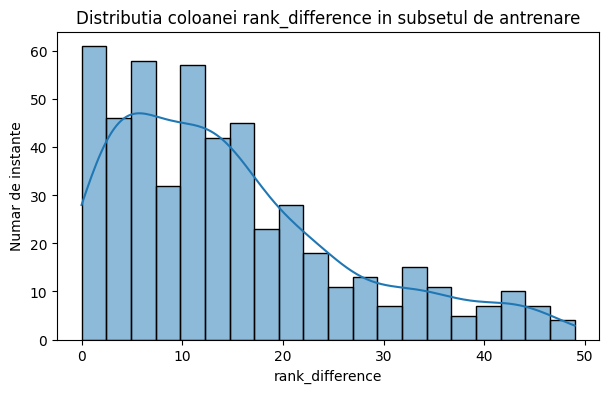


Interpretare:
Observam ca cele mai multe meciuri au rank_difference intre 0 si 15.
Acest lucru inseamna ca majoritatea meciurilor sunt intre echipe apropiate ca nivel, ceea ce creste intensitatea meciurilor.
Valorile mari apar mai rar, deci meciurile intre echipe cu diferenta de valoare foarte mare de rank sunt mai putine.

Putem afirma ca rank_difference poate ajuta modelul sa distinga meciurile echilibrate de cele dezechilibrate.
Ca preprocesare, aceasta coloana poate fi standardizata daca folosim modele sensibile la scara.



In [23]:
plt.figure(figsize=(7, 4))
sns.histplot(train_clean["rank_difference"], bins=20, kde=True)
plt.title("Distributia coloanei rank_difference in subsetul de antrenare")
plt.xlabel("rank_difference")
plt.ylabel("Numar de instante")
plt.show()

print("""
Interpretare:
Observam ca cele mai multe meciuri au rank_difference intre 0 si 15.
Acest lucru inseamna ca majoritatea meciurilor sunt intre echipe apropiate ca nivel, ceea ce creste intensitatea meciurilor.
Valorile mari apar mai rar, deci meciurile intre echipe cu diferenta de valoare foarte mare de rank sunt mai rare.

Putem afirma ca rank_difference poate ajuta modelul sa distinga meciurile echilibrate de cele dezechilibrate.
Ca preprocesare, aceasta coloana poate fi standardizata daca folosim modele sensibile la scara.
""")

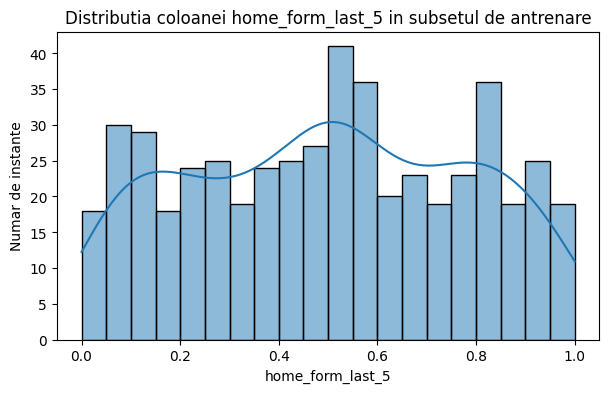


Interpretare:
Observam ca valorile pentru home_form_last_5 sunt distribuite pe intervalul 0-1.
Acest lucru este datorat faptului ca forma din ultimele 5 meciuri a echipei gazda a fost generata pe o scala de la 0 la 1.
Exista atat echipe gazda cu forma slaba, cat si echipe gazda cu forma buna, ceea ce asigura diversitate si naturalete.

O idee ce poate fi formulata este ca o forma mai buna a echipei gazda poate creste sansele de victorie.
Ca preprocesare, nu este nevoie de scalare suplimentara, deoarece valorile sunt deja in intervalul 0-1.



In [25]:
plt.figure(figsize=(7, 4))
sns.histplot(train_clean["home_form_last_5"], bins=20, kde=True)
plt.title("Distributia coloanei home_form_last_5 in subsetul de antrenare")
plt.xlabel("home_form_last_5")
plt.ylabel("Numar de instante")
plt.show()

print("""
Interpretare:
Observam ca valorile pentru home_form_last_5 sunt distribuite pe intervalul 0-1.
Acest lucru este datorat faptului ca forma din ultimele 5 meciuri a echipei gazda a fost generata pe o scala de la 0 la 1.
Exista atat echipe gazda cu forma slaba, cat si echipe gazda cu forma buna, ceea ce asigura diversitate si naturalete.

O idee ce poate fi formulata este ca o forma mai buna a echipei gazda poate creste sansele de victorie.
Ca preprocesare, nu este nevoie de scalare suplimentara, deoarece valorile sunt deja in intervalul 0-1.
""")

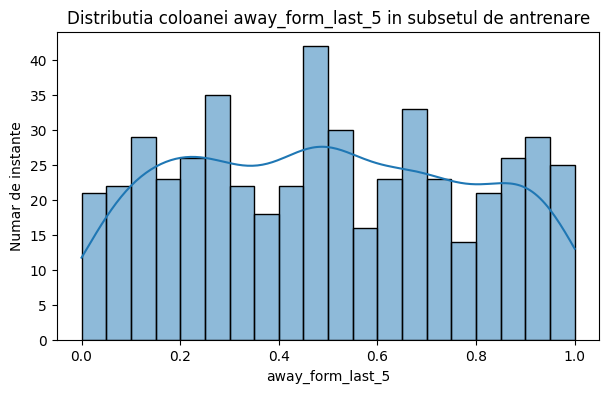


Interpretare:
Observam ca away_form_last_5 are valori intre 0 si 1, la fel ca forma echipei gazda.
Distributia arata ca in dataset exista echipe oaspete cu forme diferite, de la slabe pana la foarte bune, ceea ce arata ca datele sunt ancorate in realitate.

O concluzie este ca echipele oaspete cu forma buna pot obtine mai des rezultate pozitive.
Ca preprocesare, valorile lipsa au fost deja tratate prin imputare cu mediana, iar scalarea nu este obligatorie deoarece intervalul este deja 0-1.



In [29]:
plt.figure(figsize=(7, 4))
sns.histplot(train_clean["away_form_last_5"], bins=20, kde=True)
plt.title("Distributia coloanei away_form_last_5 in subsetul de antrenare")
plt.xlabel("away_form_last_5")
plt.ylabel("Numar de instante")
plt.show()

print("""
Interpretare:
Observam ca away_form_last_5 are valori intre 0 si 1, la fel ca forma echipei gazda.
Distributia arata ca in dataset exista echipe oaspete cu forme diferite, de la slabe pana la foarte bune, ceea ce arata ca datele sunt ancorate in realitate.

O concluzie este ca echipele oaspete cu forma buna pot obtine mai des rezultate pozitive.
Ca preprocesare, valorile lipsa au fost deja tratate prin imputare cu mediana, iar scalarea nu este obligatorie deoarece intervalul este deja 0-1.
""")

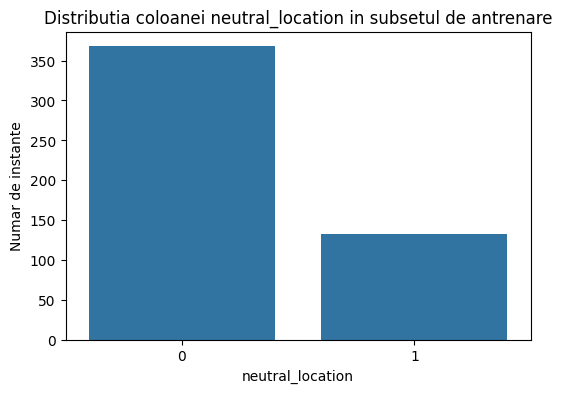


Interpretare:
Observam ca valoarea 0 apare mai des decat valoarea 1.
Valoarea 0 inseamna ca meciul nu este pe teren neutru, iar echipa gazda poate avea avantaj, fanii jucand un rol decisiv in impingerea de la spate a moralului.
Valoarea 1 inseamna ca meciul este pe teren neutru.

Aceasta distributie era de asteptat, deoarece in generarea datasetului am ales ca majoritatea meciurilor sa nu fie pe teren neutru.
Ca preprocesare, nu este necesara encodare suplimentara, deoarece variabila este deja numerica.



In [38]:
plt.figure(figsize=(6, 4))
sns.countplot(data=train_clean, x="neutral_location")
plt.title("Distributia coloanei neutral_location in subsetul de antrenare")
plt.xlabel("neutral_location")
plt.ylabel("Numar de instante")
plt.show()

print("""
Interpretare:
Observam ca valoarea 0 apare mai des decat valoarea 1.
Valoarea 0 inseamna ca meciul nu este pe teren neutru, iar echipa gazda poate avea avantaj, fanii jucand un rol decisiv in impingerea de la spate a moralului.
Valoarea 1 inseamna ca meciul este pe teren neutru.

Aceasta distributie era de asteptat, deoarece in generarea datasetului am ales ca majoritatea meciurilor sa nu fie pe teren neutru.
Ca preprocesare, nu este necesara encodare suplimentara, deoarece variabila este deja numerica.
""")

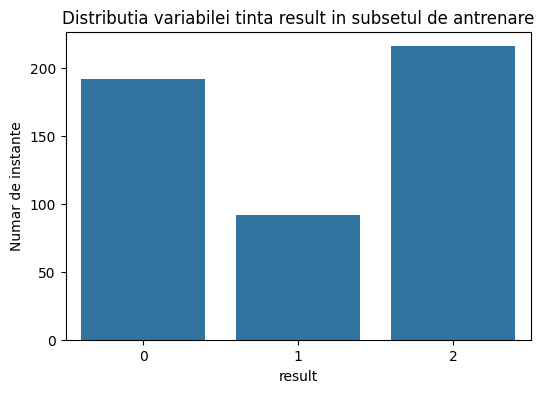


Interpretare:
Observam distributia celor trei clase ale variabilei tinta result.
Valoarea 0 inseamna victorie pentru echipa oaspete, valoarea 1 inseamna egal,
iar valoarea 2 inseamna victorie pentru echipa gazda.

Toate cele trei clase sunt prezente in subsetul de antrenare.
Daca o clasa este mai frecventa, modelul poate tinde sa o prezica mai des.
Pentru a pastra distributia claselor in train si test, am folosit parametrul stratify la impartirea datasetului.
Acest parametru face ca impartirea in train si test sa pastreze aproximativ aceeasi distributie a claselor din coloana tinta result.



In [35]:
plt.figure(figsize=(6, 4))
sns.countplot(data=train_clean, x="result")
plt.title("Distributia variabilei tinta result in subsetul de antrenare")
plt.xlabel("result")
plt.ylabel("Numar de instante")
plt.show()

print("""
Interpretare:
Observam distributia celor trei clase ale variabilei tinta result.
Valoarea 0 inseamna victorie pentru echipa oaspete, valoarea 1 inseamna egal,
iar valoarea 2 inseamna victorie pentru echipa gazda.

Toate cele trei clase sunt prezente in subsetul de antrenare.
Daca o clasa este mai frecventa, modelul poate tinde sa o prezica mai des.
Pentru a pastra distributia claselor in train si test, am folosit parametrul stratify la impartirea datasetului.
Acest parametru face ca impartirea in train si test sa pastreze aproximativ aceeasi distributie a claselor din coloana tinta result.
""")

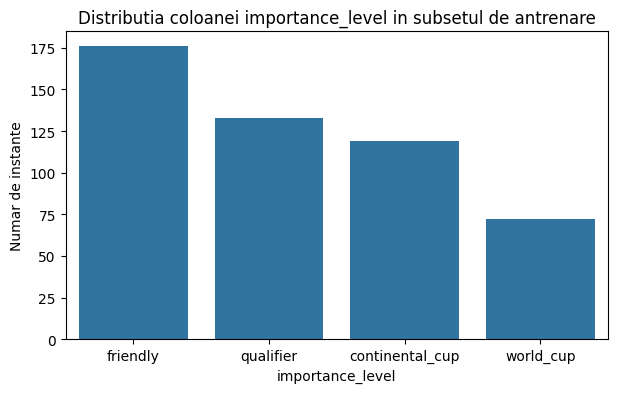


Interpretare:
Observam ca meciurile de tip friendly apar cel mai des, urmate de qualifier, continental_cup si world_cup.
Acest lucru este normal, deoarece la generarea datasetului am setat probabilitati diferite pentru tipurile de meciuri.

O idee relevanta o constituie faptul ca importanta meciului poate influenta rezultatul, deoarece meciurile mai importante au fost asociate cu un factor de intensitate mai mare.
Ca preprocesare, aceasta coloana trebuie transformata numeric prin encodare inainte de antrenarea modelului.



In [39]:
plt.figure(figsize=(7, 4))
sns.countplot(data=train_clean, x="importance_level", order=train_clean["importance_level"].value_counts().index)
plt.title("Distributia coloanei importance_level in subsetul de antrenare")
plt.xlabel("importance_level")
plt.ylabel("Numar de instante")
plt.show()

print("""
Interpretare:
Observam ca meciurile de tip friendly apar cel mai des, urmate de qualifier, continental_cup si world_cup.
Acest lucru este normal, deoarece la generarea datasetului am setat probabilitati diferite pentru tipurile de meciuri.

O idee relevanta o constituie faptul ca importanta meciului poate influenta rezultatul, deoarece meciurile mai importante au fost asociate cu un factor de intensitate mai mare.
Ca preprocesare, aceasta coloana trebuie transformata numeric prin encodare inainte de antrenarea modelului.
""")

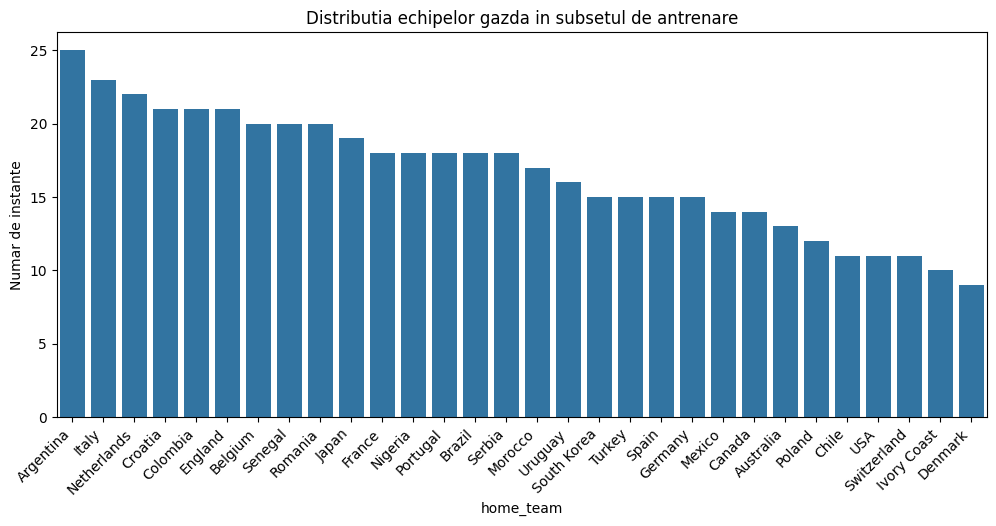


Interpretare:
Observam de cate ori apare fiecare echipa ca echipa gazda in subsetul de antrenare.
Distributia nu este perfect egala, dar echipele apar de mai multe ori, ceea ce este normal deoarece meciurile au fost generate aleator.

O idee de adus in discutie este ca unele echipe pot aparea mai des ca gazda decat altele, dar diferentele nu sunt suficient de mari pentru a elimina coloana.
Ca preprocesare, coloana home_team trebuie encodata numeric inainte de antrenarea modelului.



In [41]:
plt.figure(figsize=(12, 5))
sns.countplot(data=train_clean, x="home_team", order=train_clean["home_team"].value_counts().index)
plt.title("Distributia echipelor gazda in subsetul de antrenare")
plt.xlabel("home_team")
plt.ylabel("Numar de instante")
plt.xticks(rotation=45, ha="right")
plt.show()

print("""
Interpretare:
Observam de cate ori apare fiecare echipa ca echipa gazda in subsetul de antrenare.
Distributia nu este perfect egala, dar echipele apar de mai multe ori, ceea ce este normal deoarece meciurile au fost generate aleator.

O idee de adus in discutie este ca unele echipe pot aparea mai des ca gazda decat altele, dar diferentele nu sunt suficient de mari pentru a elimina coloana.
Ca preprocesare, coloana home_team trebuie encodata numeric inainte de antrenarea modelului.
""")

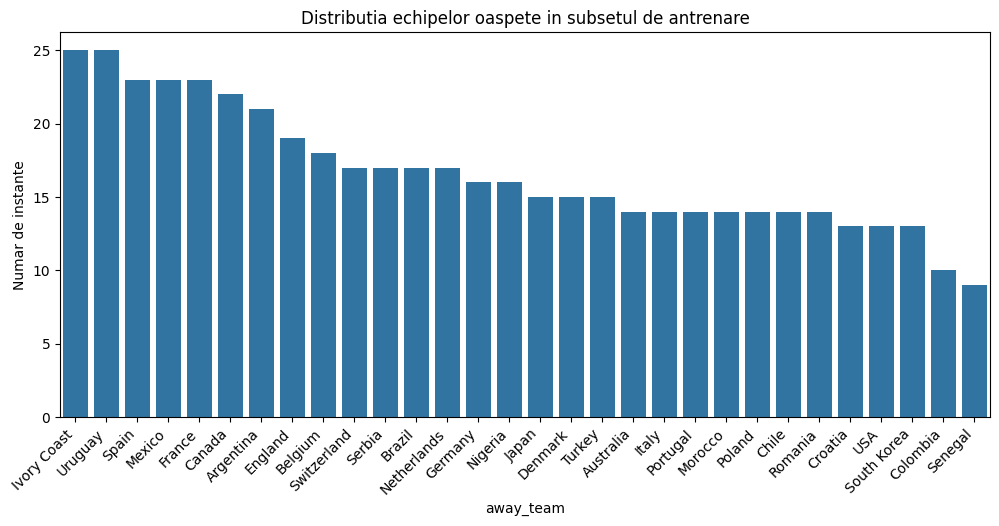


Interpretare:
Observam frecventa cu care fiecare echipa apare ca echipa oaspete.
Distributia este relativ variata, deoarece echipele au fost selectate aleator la generarea meciurilor.
OBS!! Se poate observa o similtudine cu graficul anterior, deci datele sunt generate echilibrat
Aceasta coloana poate fi utila, deoarece originea echipei poate influenta rezultatul unui meci.
Ca preprocesare, coloana away_team trebuie transformata numeric prin encodare.



In [43]:
plt.figure(figsize=(12, 5))
sns.countplot(data=train_clean, x="away_team", order=train_clean["away_team"].value_counts().index)
plt.title("Distributia echipelor oaspete in subsetul de antrenare")
plt.xlabel("away_team")
plt.ylabel("Numar de instante")
plt.xticks(rotation=45, ha="right")
plt.show()

print("""
Interpretare:
Observam frecventa cu care fiecare echipa apare ca echipa oaspete.
Distributia este relativ variata, deoarece echipele au fost selectate aleator la generarea meciurilor.
OBS!! Se poate observa o similtudine cu graficul anterior, deci datele sunt generate echilibrat
Aceasta coloana poate fi utila, deoarece originea echipei poate influenta rezultatul unui meci.
Ca preprocesare, coloana away_team trebuie transformata numeric prin encodare.
""")

In [44]:
# Detectarea outlierilor prin boxplot
# outlier = o valoare care iese foarte mult in afara valorilor medii, obisnuite intalnite intr-o coloana
outlier_columns = [
    "rank_difference", # clar pentru ca pot exista valori mari
    "home_form_last_5", # chiar daca ambele sunt intre 0-1 verificam daca distributia e normala
    "away_form_last_5"
]

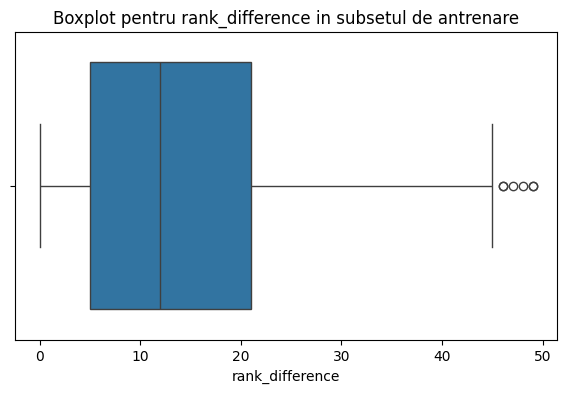


Interpretare:
Boxplot-ul pentru rank_difference arata distributia diferentelor de rank dintre echipe.
Valorile mari pot indica meciuri intre echipe cu diferente mari de nivel.

Punctele izolate din dreapta, in jurul valorilor 46-49, reprezinta posibili outlieri. Acestea corespund unor meciuri intre echipe cu diferenta mare de rank.
Totusi, aceste valori nu trebuie eliminate, deoarece sunt situatii posibile in fotbal si pot oferi informatie utila modelului.
Ca preprocesare, putem pastra aceste valori, iar pentru modele sensibile la scara putem aplica scalare.



In [49]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=train_clean["rank_difference"])
plt.title("Boxplot pentru rank_difference in subsetul de antrenare")
plt.xlabel("rank_difference")
plt.show()

print("""
Interpretare:
Boxplot-ul pentru rank_difference arata distributia diferentelor de rank dintre echipe.
Valorile mari pot indica meciuri intre echipe cu diferente mari de nivel.

Punctele izolate din dreapta, in jurul valorilor 46-49, reprezinta posibili outlieri. Acestea corespund unor meciuri intre echipe cu diferenta mare de rank.
Totusi, aceste valori nu trebuie eliminate, deoarece sunt situatii posibile in fotbal si pot oferi informatie utila modelului.
Ca preprocesare, putem pastra aceste valori, iar pentru modele sensibile la scara putem aplica scalare.
""")

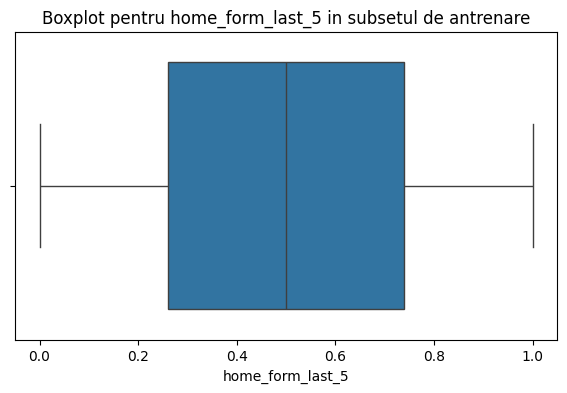


Interpretare:
Boxplot-ul pentru home_form_last_5 arata ca valorile sunt cuprinse intre 0 si 1.
Acest lucru este normal, deoarece forma recenta a echipei gazda a fost generata pe aceasta scala.
Deoarece nu apar puncte izolate in afara mustatilor boxplot-ului, inseamna ca nu avem outlieri importanti pentru aceasta variabila.

Ca preprocesare, nu este necesara eliminarea valorilor, deoarece intervalul 0-1 este valid pentru aceasta caracteristica.



In [48]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=train_clean["home_form_last_5"])
plt.title("Boxplot pentru home_form_last_5 in subsetul de antrenare")
plt.xlabel("home_form_last_5")
plt.show()

print("""
Interpretare:
Boxplot-ul pentru home_form_last_5 arata ca valorile sunt cuprinse intre 0 si 1.
Acest lucru este normal, deoarece forma recenta a echipei gazda a fost generata pe aceasta scala.
Deoarece nu apar puncte izolate in afara mustatilor boxplot-ului, inseamna ca nu avem outlieri importanti pentru aceasta variabila.

Ca preprocesare, nu este necesara eliminarea valorilor, deoarece intervalul 0-1 este valid pentru aceasta caracteristica.
""")

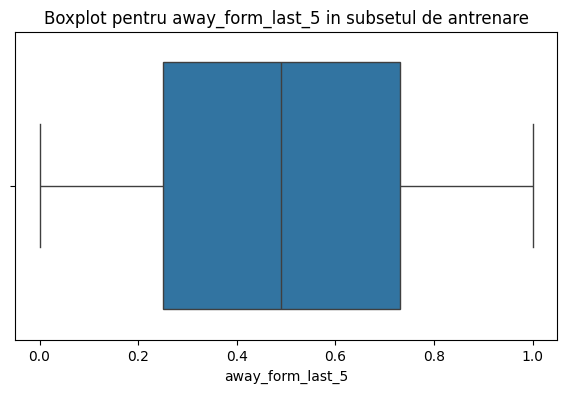


Interpretare:
Boxplot-ul pentru away_form_last_5 arata distributia formei recente a echipei oaspete.
Valorile sunt in intervalul 0-1, ceea ce corespunde modului de generare a datasetului.
Nu este necesara eliminarea valorilor extreme, deoarece 0 si 1 sunt limite normale ale scalei folosite.

Ca preprocesare, valorile lipsa au fost deja tratate prin imputare, iar coloana poate fi folosita direct in model.



In [50]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=train_clean["away_form_last_5"])
plt.title("Boxplot pentru away_form_last_5 in subsetul de antrenare")
plt.xlabel("away_form_last_5")
plt.show()

print("""
Interpretare:
Boxplot-ul pentru away_form_last_5 arata distributia formei recente a echipei oaspete.
Valorile sunt in intervalul 0-1, ceea ce corespunde modului de generare a datasetului.
Nu este necesara eliminarea valorilor extreme, deoarece 0 si 1 sunt limite normale ale scalei folosite.

Ca preprocesare, valorile lipsa au fost deja tratate prin imputare, iar coloana poate fi folosita direct in model.
""")

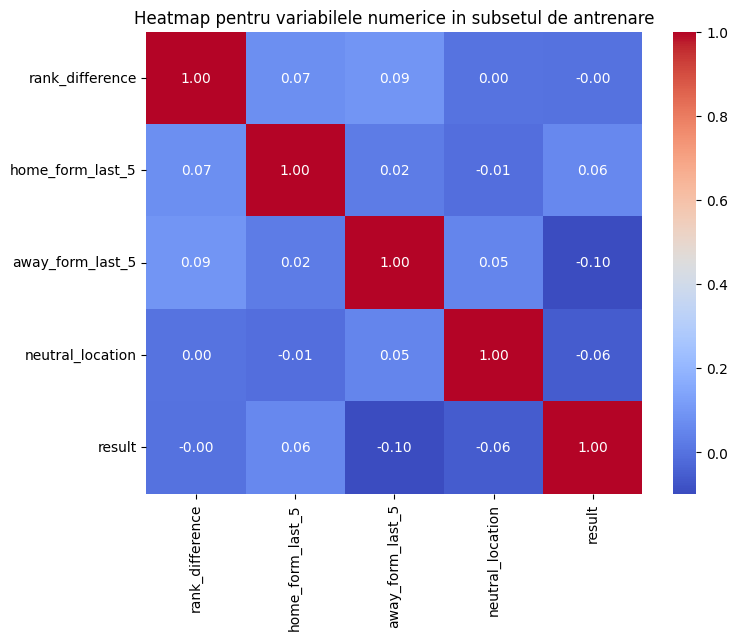


Interpretare:
Matricea de corelatii arata legaturile liniare dintre variabilele numerice.
Valorile apropiate de 1 indica o corelatie pozitiva puternica, valorile apropiate de -1 indica o corelatie negativa puternica,
iar valorile apropiate de 0 indica o legatura liniara slaba.

Observam corelatia dintre fiecare variabila si result, deoarece result este variabila tinta.
Daca o variabila are o corelatie mai mare in modul cu result, aceasta poate avea o influenta mai importanta asupra rezultatului.
Totusi, deoarece result este o variabila categorica reprezentata numeric, corelatiile trebuie interpretate cu atentie.

Ca preprocesare, daca doua variabile ar fi foarte puternic corelate intre ele, am putea lua in considerare eliminarea uneia dintre ele.
In acest caz, putem pastra variabilele, deoarece fiecare descrie un aspect diferit al meciului.



In [53]:
# Analiza corelatiilor(heatmap)
numeric_columns_for_correlation = [
    "rank_difference",
    "home_form_last_5",
    "away_form_last_5",
    "neutral_location",
    "result"
]

correlation_matrix = train_clean[numeric_columns_for_correlation].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Heatmap pentru variabilele numerice in subsetul de antrenare")
plt.show()

print("""
Interpretare:
Matricea de corelatii arata legaturile liniare dintre variabilele numerice.
Valorile apropiate de 1 indica o corelatie pozitiva puternica, valorile apropiate de -1 indica o corelatie negativa puternica,
iar valorile apropiate de 0 indica o legatura liniara slaba.

Observam corelatia dintre fiecare variabila si result, deoarece result este variabila tinta.
Daca o variabila are o corelatie mai mare in modul cu result, aceasta poate avea o influenta mai importanta asupra rezultatului.
Totusi, deoarece result este o variabila categorica reprezentata numeric, corelatiile trebuie interpretate cu atentie.

Ca preprocesare, daca doua variabile ar fi foarte puternic corelate intre ele, am putea lua in considerare eliminarea uneia dintre ele.
In acest caz, putem pastra variabilele, deoarece fiecare descrie un aspect diferit al meciului.
""")

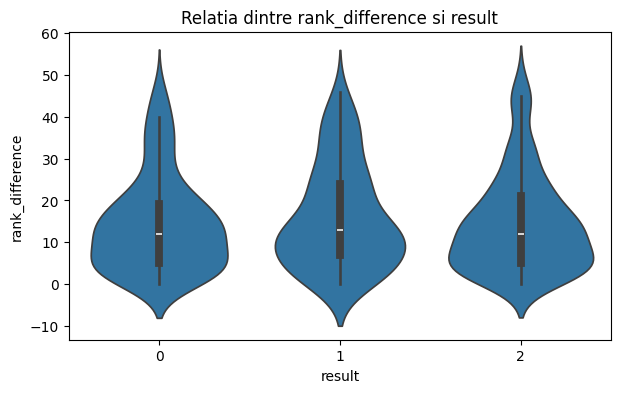


Interpretare:
Pentru toate cele trei clase, distributiile sunt destul de asemanatoare. Adica valorile lui rank_difference apar in intervale similare indiferent daca meciul este castigat de oaspete, se termina egal sau este castigat de gazda.

Mediana pare apropiata pentru toate clasele, undeva in jurul valorii 10-15. Asta sugereaza ca rank_difference, luat singur, nu separa foarte clar cele trei rezultate.

Se observa totusi ca exista valori mari ale lui rank_difference in toate clasele. Asta inseamna ca pot exista meciuri dezechilibrate ca rank in care castiga gazda, castiga oaspetele sau apare egal. Motivul este ca rank_difference este in modul, deci spune doar cat de mare este diferenta dintre echipe, nu si care echipa este mai bine clasata.



In [55]:
# Analiza relatiilor cu variabila tinta
plt.figure(figsize=(7, 4))
sns.violinplot(data=train_clean, x="result", y="rank_difference")
plt.title("Relatia dintre rank_difference si result")
plt.xlabel("result")
plt.ylabel("rank_difference")
plt.show()

print("""
Interpretare:
Pentru toate cele trei clase, distributiile sunt destul de asemanatoare. Adica valorile lui rank_difference apar in intervale similare indiferent daca meciul este castigat de oaspete, se termina egal sau este castigat de gazda.

Mediana pare apropiata pentru toate clasele, undeva in jurul valorii 10-15. Asta sugereaza ca rank_difference, luat singur, nu separa foarte clar cele trei rezultate.

Se observa totusi ca exista valori mari ale lui rank_difference in toate clasele. Asta inseamna ca pot exista meciuri dezechilibrate ca rank in care castiga gazda, castiga oaspetele sau apare egal. Motivul este ca rank_difference este in modul, deci spune doar cat de mare este diferenta dintre echipe, nu si care echipa este mai bine clasata.
""")

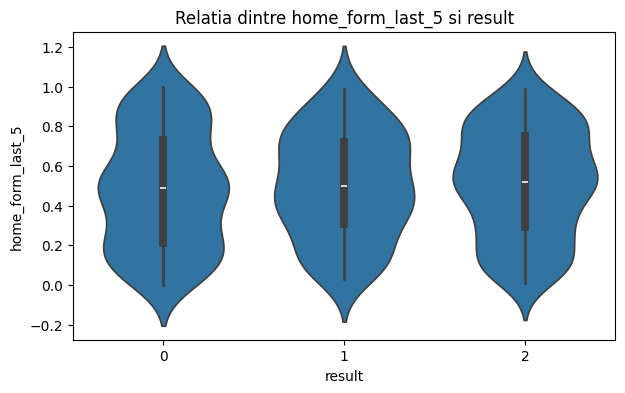


Interpretare:
Distributiile pentru cele trei clase sunt destul de asemanatoare, dar la result = 2, adica victorie pentru echipa gazda, pare ca valorile sunt usor mai concentrate spre zona medie-superioara. Asta sugereaza ca o forma mai buna a gazdei poate ajuta, dar nu explica singura rezultatul.

Pentru result = 0, adica victorie pentru oaspete, exista si multe valori mici ale lui home_form_last_5, ceea ce are sens: daca echipa gazda are forma slaba, oaspetele poate avea sanse mai mari sa castige.



In [57]:
plt.figure(figsize=(7, 4))
sns.violinplot(data=train_clean, x="result", y="home_form_last_5")
plt.title("Relatia dintre home_form_last_5 si result")
plt.xlabel("result")
plt.ylabel("home_form_last_5")
plt.show()

print("""
Interpretare:
Distributiile pentru cele trei clase sunt destul de asemanatoare, dar la result = 2, adica victorie pentru echipa gazda, pare ca valorile sunt usor mai concentrate spre zona medie-superioara. Asta sugereaza ca o forma mai buna a gazdei poate ajuta, dar nu explica singura rezultatul.

Pentru result = 0, adica victorie pentru oaspete, exista si multe valori mici ale lui home_form_last_5, ceea ce are sens: daca echipa gazda are forma slaba, oaspetele poate avea sanse mai mari sa castige.
""")

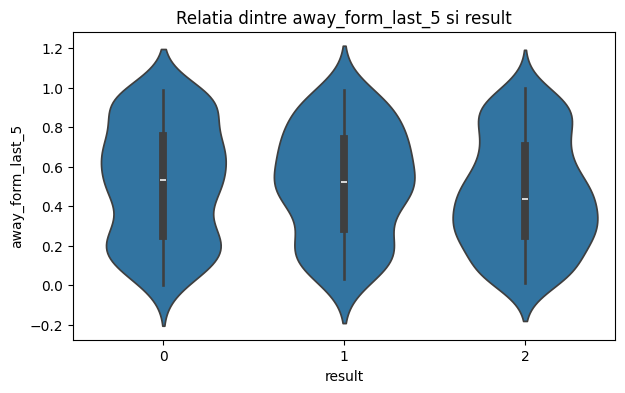


Interpretare:
Graficul arata distributia formei recente a echipei oaspete in functie de rezultatul meciului.
Daca pentru clasa 0 valorile away_form_last_5 sunt mai mari, putem suspecta ca forma buna a oaspetilor creste sansele lor de victorie.

Daca distributiile sunt apropiate intre clase, atunci away_form_last_5 nu este suficienta singura pentru a prezice rezultatul.
Ca preprocesare, coloana a fost deja imputata si este deja scalata natural intre 0 si 1.



In [58]:
plt.figure(figsize=(7, 4))
sns.violinplot(data=train_clean, x="result", y="away_form_last_5")
plt.title("Relatia dintre away_form_last_5 si result")
plt.xlabel("result")
plt.ylabel("away_form_last_5")
plt.show()

print("""
Interpretare:
Vice versa sunt asemanatoare si distributiile pentru cele trei clase in acest grafic, cu mentiunea ca la result = 2 valorile sunt concentrate spre zona median inferioara, indicand ca o forma mai buna a echipei oaspete
scade sansele de victorie a echipei gazda, dar inerent nu poate fi trasa o concluzie general valabila din asta.
De asemenea, si aici observam fenomenul de valuri mai ales in cazul result = 0, adica victorie pentru oaspete.
""")

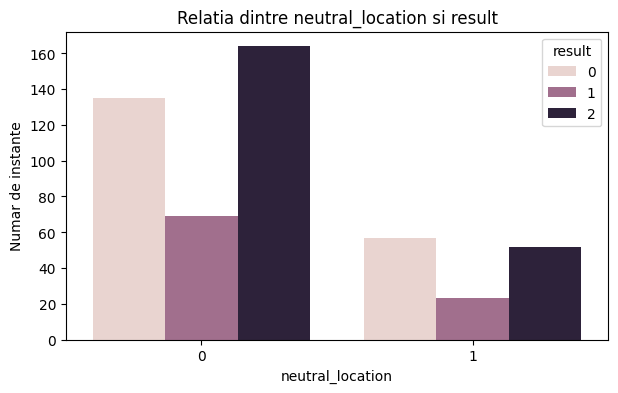


Interpretare:
Graficul compara rezultatele meciurilor in functie de terenul pe care se joaca.
Valoarea 0 inseamna ca meciul nu este pe teren neutru, iar valoarea 1 inseamna ca meciul este pe teren neutru.

Putem observa ca victoriile gazdei sunt mai frecvente atunci cand neutral_location este 0.
Acest lucru confirma ideea ca avantajul terenului propriu poate influenta rezultatul.
Ca preprocesare, coloana poate fi folosita direct, deoarece este deja numerica.



In [61]:
plt.figure(figsize=(7, 4))
sns.countplot(data=train_clean, x="neutral_location", hue="result")
plt.title("Relatia dintre neutral_location si result")
plt.xlabel("neutral_location")
plt.ylabel("Numar de instante")
plt.legend(title="result")
plt.show()

print("""
Interpretare:
Graficul compara rezultatele meciurilor in functie de terenul pe care se joaca.
Valoarea 0 inseamna ca meciul nu este pe teren neutru, iar valoarea 1 inseamna ca meciul este pe teren neutru.

Putem observa ca victoriile gazdei sunt mai frecvente atunci cand neutral_location este 0.
Acest lucru confirma ideea ca avantajul terenului propriu poate influenta rezultatul.
Ca preprocesare, coloana poate fi folosita direct, deoarece este deja numerica.
""")

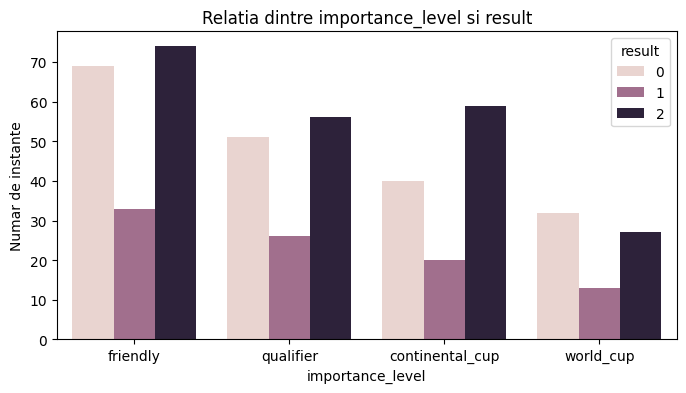


Interpretare:
Graficul arata distributia rezultatelor pentru fiecare tip de meci.
Putem observa ca indiferent de tipul meciurilor, ca vorbim despre freindly, world_cup sau continental_cup, distributiile isi pastreaza aproape mereu aceeasi forma cu exceptia World Cup.
Un argument il constitutie faptul ca la World Cup nu mai exista avantajul echipei gazda fiind teren neutru in cele mai multe cazuri ceea ce echilibreaza meciul si creste intensitatea.

O idee sugestiva este faptul ca importanta meciului poate influenta intensitatea jocului si implicit rezultatul.
Ca preprocesare, importance_level trebuie encodata numeric inainte de antrenarea modelului.



In [63]:
plt.figure(figsize=(8, 4))
sns.countplot(data=train_clean, x="importance_level", hue="result",
              order=train_clean["importance_level"].value_counts().index)
plt.title("Relatia dintre importance_level si result")
plt.xlabel("importance_level")
plt.ylabel("Numar de instante")
plt.legend(title="result")
plt.show()

print("""
Interpretare:
Graficul arata distributia rezultatelor pentru fiecare tip de meci.
Putem observa ca indiferent de tipul meciurilor, ca vorbim despre freindly, world_cup sau continental_cup, distributiile isi pastreaza aproape mereu aceeasi forma cu exceptia World Cup.
Un argument il constitutie faptul ca la World Cup nu mai exista avantajul echipei gazda fiind teren neutru in cele mai multe cazuri ceea ce echilibreaza meciul si creste intensitatea.

O idee sugestiva este faptul ca importanta meciului poate influenta intensitatea jocului si implicit rezultatul.
Ca preprocesare, importance_level trebuie encodata numeric inainte de antrenarea modelului.
""")

In [64]:
# Antrenarea si evaluarea unui model de baza - Random Forest

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# separam caracteristicile de variabila tinta result
X_train = train_clean.drop("result", axis=1)
y_train = train_clean["result"]

X_test = test_clean.drop("result", axis=1)
y_test = test_clean["result"]

numeric_columns = [
    "rank_difference",
    "home_form_last_5",
    "away_form_last_5",
    "neutral_location"
]

categorical_columns = [
    "home_team",
    "away_team",
    "importance_level"
]

# preprocesarea presupune encodarea valorilor categoriale
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("numeric", "passthrough", numeric_columns)
    ]
)

# modelul de baza
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            random_state=RANDOM_SEED
        ))
    ]
)
# antrenare
model.fit(X_train, y_train)
# predicitii initiale
y_pred = model.predict(X_test)

# metricile
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("Rezultatele modelului RandomForestClassifier:")
print(f"Acuratete: {accuracy:.4f}")
print(f"Precizie: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

print("\nRaport de clasificare:")
print(classification_report(y_test, y_pred))

Rezultatele modelului RandomForestClassifier:
Acuratete: 0.4400
Precizie: 0.3716
Recall: 0.4400
F1-score: 0.4029

Raport de clasificare:
              precision    recall  f1-score   support

           0       0.44      0.52      0.48        77
           1       0.00      0.00      0.00        37
           2       0.47      0.56      0.51        86

    accuracy                           0.44       200
   macro avg       0.30      0.36      0.33       200
weighted avg       0.37      0.44      0.40       200



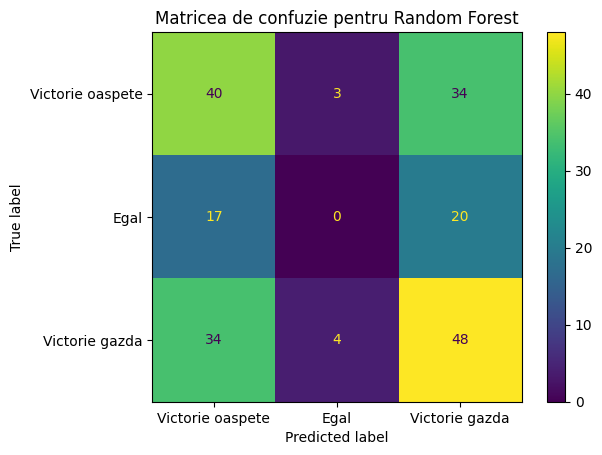


Interpretare:
Acest model nu a reiesit a fi prea reusit, insa e ceva normal fiind doar de baza.
Matricea de confuzie arata cate exemple au fost clasificate corect si cate au fost confundate intre clase.
Valorile de pe diagonala principala reprezinta predictii corecte, observam ca la egal nu am prezis nimic corect.
Valorile din afara diagonalei reprezinta erori ale modelului.

Modelul nu a identificat corect egalurile, deoarece aceasta clasa este mai putin reprezentata si mai greu de separat de celelalte rezultate. Datasetul final nu include toate variabilele interne folosite la generarea golurilor, precum expected_goals_home, expected_goals_away sau fortele ofensive si defensive. 
Din acest motiv, modelul are mai multe informatii pentru a distinge victoriile, dar mai putine pentru a recunoaste situatiile de egalitate. Pentru egaluri, ar fi util sa stim daca echipele sunt apropiate ca valoare, dar si daca avantajele sunt echilibrate intre gazda si oaspete.
Acest lucru este normal in co

In [68]:
# Matricea de confuzie

mat = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=mat,
    display_labels=["Victorie oaspete", "Egal", "Victorie gazda"]
)

disp.plot()
plt.title("Matricea de confuzie pentru Random Forest")
plt.show()

print("""
Interpretare:
Acest model nu a reiesit a fi prea reusit, insa e ceva normal fiind doar de baza.
Matricea de confuzie arata cate exemple au fost clasificate corect si cate au fost confundate intre clase.
Valorile de pe diagonala principala reprezinta predictii corecte, observam ca la egal nu am prezis nimic corect.
Valorile din afara diagonalei reprezinta erori ale modelului.

Modelul nu a identificat corect egalurile, deoarece aceasta clasa este mai putin reprezentata si mai greu de separat de celelalte rezultate. Datasetul final nu include toate variabilele interne folosite la generarea golurilor, precum expected_goals_home, expected_goals_away sau fortele ofensive si defensive.
Din acest motiv, modelul are mai multe informatii pentru a distinge victoriile, dar mai putine pentru a recunoaste situatiile de egalitate. Pentru egaluri, ar fi util sa stim daca echipele sunt apropiate ca valoare, dar si daca avantajele sunt echilibrate intre gazda si oaspete.
Acest lucru este normal in contextul fotbalului, deoarece rezultatul de egalitate este adesea mai dificil de separat clar fata de victorii.
""")